# Dry Bean Dataset Documentation

## 1. Overview
- **Source:** [UCI Machine Learning Repository — Dry Bean Dataset](https://archive.ics.uci.edu/dataset/602/dry+bean+dataset)
- **DOI:** `10.24432/C50S4B`
- **Subject Area:** Biology / Computer Vision
- **Task:** Multi-class Classification (Distinguishing between **7** registered dry bean varieties)
- **Dataset Size:** 13,611 instances (grain images) | **Missing Values:** None (`0`)
- **Input Features:** 16 continuous/integer morphological features extracted via computer vision segmentation (12 dimensional features + 4 shape factors)
- **Target Feature:** `Class` (`Seker`, `Barbunya`, `Bombay`, `Cali`, `Dermosan`, `Horoz`, `Sira`)

---

## 2. Feature Dictionary

### A. Dimensional & Geometric Features (12 Features)

| Feature | Symbol | Data Type | Units | Description |
| :--- | :---: | :--- | :---: | :--- |
| **Area** | $A$ | Integer | `pixels` | The area of a bean zone and the total number of pixels within its boundaries. |
| **Perimeter** | $P$ | Float | `pixels` | Bean circumference, defined as the length of its outer border. |
| **MajorAxisLength** | $L$ | Float | `pixels` | Distance between the ends of the longest line that can be drawn from a bean. |
| **MinorAxisLength** | $l$ | Float | `pixels` | Longest line that can be drawn from the bean perpendicular to the main axis. |
| **AspectRatio** | $K$ | Float | — | Defines the relationship between major and minor axis lengths ($K = L / l$). |
| **Eccentricity** | $Ec$ | Float | — | Eccentricity of the ellipse having the same second moments as the bean region ($0 \le Ec < 1$). |
| **ConvexArea** | $C$ | Integer | `pixels` | Number of pixels in the smallest convex polygon enclosing the bean seed area. |
| **EquivDiameter** | $Ed$ | Float | `pixels` | Diameter of a circle having the same area as the bean seed ($Ed = \sqrt{4A / \pi}$). |
| **Extent** | $Ex$ | Float | — | Ratio of the pixels in the bounding box to the bean area. |
| **Solidity** | $S$ | Float | — | Also known as convexity; ratio of pixels in the convex shell to those found in the bean ($A / C$). |
| **Roundness** | $R$ | Float | — | Measures how closely the shape approaches a circle: $R = \frac{4\pi A}{P^2}$. |
| **Compactness** | $CO$ | Float | — | Measures the compactness/roundness of the bean object: $CO = \frac{Ed}{L}$. |

### B. Shape Form Factors (4 Features)

| Feature | Symbol | Data Type | Formula / Description |
| :--- | :---: | :--- | :--- |
| **ShapeFactor1** | $SF1$ | Float | $L / A$ — Ratio of major axis length to area. |
| **ShapeFactor2** | $SF2$ | Float | $l / A$ — Ratio of minor axis length to area. |
| **ShapeFactor3** | $SF3$ | Float | $\frac{A}{(L/2)^2 \pi}$ — Ratio of area to the area of a circle with diameter $L$. |
| **ShapeFactor4** | $SF4$ | Float | $\frac{A}{(L/2)(l/2)\pi}$ — Ratio of area to the area of an ellipse with axes $L$ and $l$. |

### C. Target Variable

| Feature | Data Type | Classes (7 Varieties) |
| :--- | :--- | :--- |
| **Class** | Categorical (String) | `Seker`, `Barbunya`, `Bombay`, `Cali`, `Dermosan`, `Horoz`, `Sira` |

---

## 3. Quick Load in Python (`ucimlrepo`)

```python
# pip install ucimlrepo
from ucimlrepo import fetch_ucirepo

dry_bean = fetch_ucirepo(id=602)
X = dry_bean.data.features  # Shape: (13611, 16)
y = dry_bean.data.targets   # Shape: (13611, 1)

# 1. Setup & Configuration

In [302]:
import os
import copy
import random
from pathlib import Path 

import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, f1_score, confusion_matrix
import torch
import torch.nn as nn
from torch.nn import CrossEntropyLoss
from torch.utils.data import Dataset, DataLoader
from torch.optim import Adam


# Reproducibility setup
def seed_everything(seed: int = 42) -> None:
    random.seed(seed)                           # Python built-in RNG
    os.environ["PYTHONHASHSEED"] = str(seed)    # Hash-based operations (e.g., sets, worker processes)
    np.random.seed(seed)                        # NumPy global RNG
    torch.manual_seed(seed)                     # PyTorch CPU RNG (weights init, dropout, DataLoader shuffle)
    torch.cuda.manual_seed(seed)                # PyTorch current GPU RNG
    torch.cuda.manual_seed_all(seed)            # PyTorch all GPUs RNG (safe on single-GPU or CPU)


SEED = 42
seed_everything(seed=SEED)


# Device configuration
device = 'cuda' if torch.cuda.is_available() else 'cpu' 

# Data path resolution (works from project root or notebooks/ subdirectory)
CURRENT_DIR = Path.cwd()
PROJECT_ROOT = CURRENT_DIR if (CURRENT_DIR / "data").exists() else CURRENT_DIR.parent
DATA_PATH = PROJECT_ROOT / "data" / "Dry_Bean_Dataset.xlsx"

assert DATA_PATH.exists(), f"Dataset not found at: {DATA_PATH}"

# 2. Data Loading & Understanding

In [303]:
data = pd.read_excel(DATA_PATH)
display(data.sample(7))
display(data.shape)

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
1488,42339,741.226,260.199331,207.306394,1.255144,0.604347,42676,232.180294,0.771202,0.992103,0.968387,0.892317,0.006146,0.002403,0.796230,0.999383,SEKER
2611,68247,1088.754,370.368146,237.863792,1.557060,0.766507,70172,294.779204,0.767683,0.972567,0.723492,0.795909,0.005427,0.001343,0.633471,0.986352,BARBUNYA
749,37856,708.716,248.430330,194.360324,1.278195,0.622835,38232,219.544429,0.744640,0.990165,0.947109,0.883726,0.006563,0.002469,0.780972,0.998235,SEKER
99,33143,648.385,222.526310,189.737379,1.172812,0.522480,33377,205.423899,0.769980,0.992989,0.990685,0.923144,0.006714,0.003008,0.852195,0.999465,SEKER
11298,29925,647.570,237.714031,161.004848,1.476440,0.735703,30321,195.196551,0.785309,0.986940,0.896748,0.821140,0.007944,0.002228,0.674271,0.995521,DERMASON
868,38489,707.978,244.119399,200.950084,1.214826,0.567805,38782,221.372349,0.788871,0.992445,0.964955,0.906820,0.006343,0.002646,0.822322,0.998979,SEKER
5382,89592,1155.357,452.291405,254.964533,1.773939,0.825968,90627,337.745581,0.795772,0.988580,0.843425,0.746743,0.005048,0.000968,0.557626,0.989193,CALI


(13611, 17)

In [304]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  str    
dtypes: float64(14), int64(2

In [305]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.284549,29324.095717,20420.000000,36328.000000,44652.000000,61332.000000,254616.000000
Perimeter,13611.0,855.283459,214.289696,524.736000,703.523500,794.941000,977.213000,1985.370000
MajorAxisLength,13611.0,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860153
MinorAxisLength,13611.0,202.270714,44.970091,122.512653,175.848170,192.431733,217.031741,460.198497
AspectRation,13611.0,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,53768.200206,29774.915817,20684.000000,36714.500000,45178.000000,62294.000000,263261.000000
EquivDiameter,13611.0,253.064220,59.177120,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,0.987143,0.004660,0.919246,0.985670,0.988283,0.990013,0.994677


In [306]:
# Null Values
print(f"None Values: ")
display(data.isnull().sum())

# Duplicated
print(f"\nDuplicates:")
display(data.duplicated().sum())

None Values: 


Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64


Duplicates:


np.int64(68)

In [307]:
# Display all duplicate pairs stacked together
dups = data[data.duplicated(keep=False)].sort_values(by=list(data.columns))
display(dups.head(6))  # Shows the first 3 identical pairs (6 rows)

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
5504,33518,702.956,277.571399,154.305581,1.798842,0.831240,34023,206.582775,0.808383,0.985157,0.852377,0.744251,0.008281,0.001567,0.553909,0.996396,HOROZ
5505,33518,702.956,277.571399,154.305581,1.798842,0.831240,34023,206.582775,0.808383,0.985157,0.852377,0.744251,0.008281,0.001567,0.553909,0.996396,HOROZ
5508,33954,716.750,277.368480,156.356326,1.773951,0.825970,34420,207.922042,0.799482,0.986461,0.830549,0.749624,0.008169,0.001591,0.561936,0.996847,HOROZ
5509,33954,716.750,277.368480,156.356326,1.773951,0.825970,34420,207.922042,0.799482,0.986461,0.830549,0.749624,0.008169,0.001591,0.561936,0.996847,HOROZ
5547,38427,756.323,306.533886,160.591784,1.908777,0.851782,38773,221.193978,0.796976,0.991076,0.844174,0.721597,0.007977,0.001334,0.520702,0.993905,HOROZ
5548,38427,756.323,306.533886,160.591784,1.908777,0.851782,38773,221.193978,0.796976,0.991076,0.844174,0.721597,0.007977,0.001334,0.520702,0.993905,HOROZ


In [308]:
# Drop Duplicate
data = data.drop_duplicates().reset_index(drop=True)

In [309]:
data.duplicated().sum()

np.int64(0)

In [310]:
# Target analysis
display(data['Class'].describe())

display(data["Class"].value_counts())

count        13543
unique           7
top       DERMASON
freq          3546
Name: Class, dtype: object

Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1860
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

# 3. Data Processing

In [311]:
# 1. Split The data (train/dev/test)
X , y = data.drop(columns='Class'), data['Class']

# temp(Train & dev) / test set
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.15, random_state=42, stratify=y)

# train/dev split
X_train, X_dev, y_train, y_dev = train_test_split(X_temp, y_temp, test_size=0.2, random_state=42, stratify=y_temp)


# 2. Encoding (Target Label Encoding)
encoder = LabelEncoder()

y_train_encoded = encoder.fit_transform(y_train)
y_dev_encoded = encoder.transform(y_dev)
y_test_encoded = encoder.transform(y_test)

class_names = encoder.classes_


# 3. Scaling 

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_dev_scaled = scaler.transform(X_dev)
X_test_scaled = scaler.transform(X_test)


# 4. Convert to PyTorch Tensors 
# Features
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float)
X_dev_tensor = torch.tensor(X_dev_scaled, dtype=torch.float)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float)

# Target
y_train_tensor = torch.tensor(y_train_encoded, dtype=torch.long)
y_dev_tensor = torch.tensor(y_dev_encoded, dtype=torch.long)
y_test_tensor = torch.tensor(y_test_encoded, dtype=torch.long)

In [312]:
display(pd.DataFrame(X_train_scaled, columns=data.columns[:-1]).head())
display(pd.Series(y_train_encoded).head())

display(pd.DataFrame(X_dev_scaled, columns=data.columns[: -1]).head())
display(pd.Series(y_dev_encoded).head())

display(pd.DataFrame(X_test_scaled, columns=data.columns[:-1]).head())
display(pd.Series(y_test_encoded).head())

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,0.719443,0.891458,1.029979,0.759870,0.588426,0.704413,0.757971,0.916303,0.532386,-3.468020,-0.374571,-0.772285,-0.937848,-1.057569,-0.785858,-3.947719
1,-1.024797,-1.344307,-1.311718,-1.354157,-0.464377,-0.203009,-1.022656,-1.386744,0.788087,-0.238804,0.408502,0.378574,2.204685,1.432226,0.344852,0.029144
2,-0.481860,-0.475669,-0.453179,-0.576581,0.049845,0.307297,-0.481340,-0.514831,-1.065156,-0.070066,-0.196730,-0.139919,0.588989,0.055663,-0.177117,0.867132
3,0.722159,0.793347,0.824937,0.917046,0.089247,0.340412,0.712312,0.919091,1.198437,0.627531,0.243774,-0.212966,-1.152357,-0.796106,-0.248999,-0.365119
4,0.902278,1.016789,1.096686,0.996725,0.378855,0.563112,0.902507,1.100720,-0.180814,-0.253518,-0.094262,-0.511273,-1.202763,-1.005117,-0.538309,-1.225905


0    2
1    3
2    6
3    2
4    2
dtype: int64

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,-0.443690,-0.552527,-0.636192,-0.223019,-0.822348,-0.671818,-0.446987,-0.461056,0.857529,0.528055,0.912440,0.820004,0.062320,0.712514,0.805466,0.738235
1,-0.204346,-0.255362,-0.328754,0.079798,-0.672880,-0.461931,-0.208056,-0.139827,0.445285,0.433459,0.847234,0.631004,-0.319657,0.297403,0.606426,0.449791
2,0.345248,0.718331,1.196574,-0.249033,2.569453,1.543961,0.334264,0.516723,-0.321037,0.937476,-1.597921,-2.101264,0.108725,-1.482877,-1.965386,0.328809
3,1.164918,1.389649,1.553701,1.041425,0.965233,0.924450,1.202451,1.355041,0.297645,-2.952999,-0.833282,-1.052733,-1.212528,-1.314161,-1.046027,-2.602179
4,-0.629344,-0.743385,-0.862346,-0.486542,-0.890529,-0.775371,-0.629555,-0.730305,1.290298,0.115836,0.411288,0.855344,0.493127,1.017150,0.842987,-0.905577


0    3
1    6
2    4
3    2
4    3
dtype: int64

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,-0.488550,-0.619114,-0.595266,-0.417156,-0.475840,-0.216333,-0.492177,-0.524336,0.996470,0.617213,1.002442,0.411193,0.342757,0.458522,0.378379,0.710996
1,-0.666869,-0.814568,-0.825585,-0.686992,-0.522148,-0.271187,-0.666149,-0.787261,-0.813371,-0.042188,0.595627,0.458058,0.784564,0.749928,0.426689,0.519020
2,-0.597830,-0.807005,-1.059907,-0.106612,-1.722783,-2.680088,-0.601223,-0.683172,0.853279,0.674394,1.457851,2.084082,-0.094311,2.082863,2.207023,0.771305
3,-0.507940,-0.570296,-0.619112,-0.409816,-0.532000,-0.283075,-0.499703,-0.552023,-0.899902,-1.344157,0.323340,0.414034,0.387285,0.485671,0.381303,-1.376303
4,0.505874,0.748464,0.744847,0.547115,0.446257,0.610219,0.499271,0.692198,-1.321236,0.425484,-0.786942,-0.554787,-0.806560,-0.870789,-0.579940,-0.565303


0    6
1    3
2    5
3    6
4    2
dtype: int64

In [313]:
print("============================== Features Tensors ===================================")
print(f"[INFO] Train: {X_train_tensor, X_train_tensor.shape}")
print(f"[INFO] Dev: {X_dev_tensor, X_dev_tensor.shape}")
print(f"[INFO] Test: {X_test_tensor, X_test_tensor.shape}")

print("\n============================== Features Tensors ===================================")
print(f"[INFO] Train: {y_train_tensor, y_train_tensor.shape}")
print(f"[INFO] Dev: {y_dev_tensor, y_dev_tensor.shape}")
print(f"[INFO] Test: {y_dev_tensor, y_dev_tensor.shape}")

============================== Features Tensors ===================================
[INFO] Train: (tensor([[ 0.7194,  0.8915,  1.0300,  ..., -1.0576, -0.7859, -3.9477],
        [-1.0248, -1.3443, -1.3117,  ...,  1.4322,  0.3449,  0.0291],
        [-0.4819, -0.4757, -0.4532,  ...,  0.0557, -0.1771,  0.8671],
        ...,
        [ 0.2083,  0.6783,  1.2260,  ..., -1.5961, -2.3077, -0.2622],
        [-0.1185, -0.0787, -0.0903,  ..., -0.1502,  0.0347, -0.1460],
        [ 0.8421,  1.0169,  1.1802,  ..., -1.1397, -0.8699, -0.6592]]), torch.Size([9208, 16]))
[INFO] Dev: (tensor([[-0.4437, -0.5525, -0.6362,  ...,  0.7125,  0.8055,  0.7382],
        [-0.2043, -0.2554, -0.3288,  ...,  0.2974,  0.6064,  0.4498],
        [ 0.3452,  0.7183,  1.1966,  ..., -1.4829, -1.9654,  0.3288],
        ...,
        [-0.1954, -0.1267,  0.0612,  ..., -0.5770, -0.7575, -0.1200],
        [-0.0765,  0.0212,  0.1515,  ..., -0.5753, -0.6152, -0.7471],
        [-0.6580, -0.8209, -0.8363,  ...,  0.8193,  0.5331,  0.708

# 4. Dataset & Data Loader

In [314]:
# Dataset class
class DryBeanDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        return self.X[index], self.y[index]


# Dataset
train_dataset = DryBeanDataset(X_train_tensor, y_train_tensor)
dev_dataset = DryBeanDataset(X_dev_tensor, y_dev_tensor)
test_dataset = DryBeanDataset(X_test_tensor, y_test_tensor)

# DataLoader
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
dev_loader = DataLoader(dev_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

# Check one batch
train_features_batch, train_labels_batch = next(iter(train_loader))

print(f"Train Features shape: {train_features_batch.shape}")
print(f"Train Features dtype: {train_features_batch.dtype}\n")

print(f"Train Labels shape: {train_labels_batch.shape}")
print(f"Train Labels dtype: {train_labels_batch.dtype}\n\n")


dev_features_batch, dev_labels_batch = next(iter(dev_loader))

print(f"Dev Features shape: {dev_features_batch.shape}")
print(f"Dev Features dtype: {dev_features_batch.dtype}\n")

print(f"Dev Labels shape: {dev_labels_batch.shape}")
print(f"Dev Labels dtype: {dev_labels_batch.dtype}")

Train Features shape: torch.Size([64, 16])
Train Features dtype: torch.float32

Train Labels shape: torch.Size([64])
Train Labels dtype: torch.int64


Dev Features shape: torch.Size([64, 16])
Dev Features dtype: torch.float32

Dev Labels shape: torch.Size([64])
Dev Labels dtype: torch.int64


# 5. Build Model Architecture

In [315]:
# NN Class
class DryBeenClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        # 1. Input Layer
        self.layer1 = nn.Linear(in_features=16, out_features=32)


        # 2. 1st Hidden Layer
        self.layer2 = nn.Linear(in_features=32, out_features=16)

        # 3. 2nd Hidden Layer 
        self.layer3 = nn.Linear(in_features=16, out_features=8)

        # 4. Output Layer 
        self.layer4 = nn.Linear(in_features=8, out_features=7)

        # ReLU Activation 
        self.relu = nn.ReLU()


    def forward(self, X:torch.Tensor) -> torch.Tensor:
        # 1. Input layer
        X = self.layer1(X)
        X = self.relu(X)

        # 2. 1st Hidden Layer
        X = self.layer2(X)
        X = self.relu(X)

        # 3. 2nd Hidden Layer
        X = self.layer3(X)
        X = self.relu(X)

        # 4. Output Layer
        X = self.layer4(X)

        return X

In [316]:
# Instantiate a Model from the class
model = DryBeenClassifier()

# Load model to device
model.to(device)

# Trainable/Learnable Model Parameters
total_learnable_parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)      # .numel() stands for NUmber of ELements (count all elements in each p tensor **p is now a list of tensor if we used len(p) this will gives the number of tensors)

print("================= MODEL DETAILS =====================")
print(f"Model Details: {model}")
print(f"Total Learnable Model Parameters: {total_learnable_parameters}")
print(f"Model device: {next(model.parameters()).device}")


# Checking the models output
features_batch, labels_batch = next(iter(train_loader))
features_batch, labels_batch = features_batch.to(device), labels_batch.to(device)

# Pass a Sample batch to the model
sample = model(features_batch)

print(f"================ CHECKING THE MODEL OUTPUT.... ====================")
print(f"Input batch shape: {features_batch.shape}")             # Should be [64, 16]
print(f"Output batch shape: {sample.shape}")                    # Should be [64, 7]

================= MODEL DETAILS =====================
Model Details: DryBeenClassifier(
  (layer1): Linear(in_features=16, out_features=32, bias=True)
  (layer2): Linear(in_features=32, out_features=16, bias=True)
  (layer3): Linear(in_features=16, out_features=8, bias=True)
  (layer4): Linear(in_features=8, out_features=7, bias=True)
  (relu): ReLU()
)
Total Learnable Model Parameters: 1271
Model device: cuda:0
================ CHECKING THE MODEL OUTPUT.... ====================
Input batch shape: torch.Size([64, 16])
Output batch shape: torch.Size([64, 7])


# 6. Train / Eval

In [317]:
# Define the Loss function 
criterion = CrossEntropyLoss()

# Define the Optimizer
optimizer = Adam(params=model.parameters(), lr=0.01, weight_decay=0.0003)

## 6.2. Training Step 

In [318]:
# 1. Train Function
def train_step(model, data_loader, optimizer, criterion, device):

    # Put model in train mode
    model.train()

    # Loss for learning tracking & correct for acc
    total_loss = 0.0
    correct = 0

    # Training Loop
    for features, labels in data_loader:

        # 1. Load data to cuda
        features, labels = features.to(device), labels.to(device)

        # 2. Forward Pass
        outputs = model(features)

        # 3. Calc Loss
        loss = criterion(outputs, labels)

        # 4. Clear The optimizer from past grads
        optimizer.zero_grad(set_to_none=True)

        # 5. Backward
        loss.backward()

        # 6. Take a step (update the parameters with new values) 
        optimizer.step()

        preds = outputs.argmax(dim=1)               # or _, preds = torch.max(outputs, 1)
        total_loss += loss.item() * labels.size(0)
        correct += (preds == labels).sum().item()

    avg_loss = total_loss / len(data_loader.dataset)
    acc = correct / len(data_loader.dataset)
    return avg_loss, acc




## 6.2. Eval Step

In [319]:
# 2. Eval Function
@torch.inference_mode()
def eval_step(model, data_loader, criterion, device, return_preds=False):

    # Put The model in evaluation mode
    model.eval()

    # Loss for comparing with train & correct for eval acc
    total_loss = 0.0
    correct = 0

    # For future test(test_loader) not for validation (dev_loader)
    all_preds = []
    all_labels = []

    # Eval loop
    for features, labels in data_loader:
        
        # 1. Load Data To Device
        features, labels = features.to(device), labels.to(device)

        # 2. Forward pass
        outputs = model(features)

        # 3. Calc Loss
        loss = criterion(outputs, labels)

        # 4. Metric eval
        preds = outputs.argmax(dim=1)
        total_loss += loss.item() * labels.size(0)
        correct += (preds == labels).sum().item()
    # For future test(test_loader) not for validation (dev_loader)
        if return_preds:
            all_preds.append(preds.cpu())
            all_labels.append(labels.cpu())

    avg_loss = total_loss / len(data_loader.dataset)
    acc = correct / len(data_loader.dataset)

    # For future test(test_loader) not for validation (dev_loader)
    if return_preds:
            y_true = torch.cat(all_labels).numpy()
            y_preds = torch.cat(all_preds).numpy()
            return avg_loss, acc, y_true, y_preds
    
    return avg_loss, acc


## 6.3. Put Them Together

In [320]:
# 3. Put Them together for Training and Validation (fit them to the data)
def fit(model, train_loader, dev_loader, epochs, optimizer, criterion, device):

    # 1. Save the history among epochs
    history = {"train_loss":[],
               "train_acc":[],
               "dev_loss":[],
               "dev_acc":[]
               }
    best_dev_loss = float("inf")

    # 2. Save best Model weights
    best_model_weights = copy.deepcopy(model.state_dict())

    # 3. Train and eval among n of epochs
    for epoch in range(1, epochs+1):

        # train Step
        train_loss, train_acc = train_step(model=model,
                                            data_loader=train_loader, 
                                            optimizer=optimizer, 
                                            criterion=criterion, 
                                            device=device
                                        )

        # eval_step
        dev_loss, dev_acc = eval_step(model=model,
                                        data_loader=dev_loader,
                                        criterion=criterion,
                                        device=device
                                    )

        # Save The loss and acc of train and dev
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["dev_loss"].append(dev_loss)
        history["dev_acc"].append(dev_acc)

        # Save The Best Model Weights Based on dev_loss
        if dev_loss < best_dev_loss:
            best_dev_loss = dev_loss
            best_model_weights = copy.deepcopy(model.state_dict())
        
        if epoch % 10 == 0 or epoch == 1:
            print(
                f"Epoch [{epoch:03d} / {epochs:03d}] | " 
                f"Train Loss: {train_loss:.4f}, Train Accuracy: {train_acc:.4f} | " 
                f"Dev Loss: {dev_loss:.4f}, Dev Accuracy: {dev_acc:.4f}" 
            )

    # 4. Load Bes Model Weights
    model.load_state_dict(best_model_weights)
    return history

## 6.4. Train And Eval Process

In [321]:
# Train and Eval
history = fit(model=model,
              train_loader=train_loader,
              dev_loader=dev_loader,
              epochs=100,
              optimizer=optimizer,
              criterion=criterion,
              device=device
            )

Epoch [001 / 100] | Train Loss: 0.4981, Train Accuracy: 0.8164 | Dev Loss: 0.2590, Dev Accuracy: 0.9084
Epoch [010 / 100] | Train Loss: 0.1998, Train Accuracy: 0.9292 | Dev Loss: 0.2061, Dev Accuracy: 0.9223
Epoch [020 / 100] | Train Loss: 0.1934, Train Accuracy: 0.9311 | Dev Loss: 0.1897, Dev Accuracy: 0.9271
Epoch [030 / 100] | Train Loss: 0.1895, Train Accuracy: 0.9300 | Dev Loss: 0.1962, Dev Accuracy: 0.9249
Epoch [040 / 100] | Train Loss: 0.1851, Train Accuracy: 0.9334 | Dev Loss: 0.1910, Dev Accuracy: 0.9271
Epoch [050 / 100] | Train Loss: 0.1876, Train Accuracy: 0.9298 | Dev Loss: 0.1988, Dev Accuracy: 0.9253
Epoch [060 / 100] | Train Loss: 0.1791, Train Accuracy: 0.9334 | Dev Loss: 0.1970, Dev Accuracy: 0.9249
Epoch [070 / 100] | Train Loss: 0.1783, Train Accuracy: 0.9333 | Dev Loss: 0.1998, Dev Accuracy: 0.9257
Epoch [080 / 100] | Train Loss: 0.1759, Train Accuracy: 0.9351 | Dev Loss: 0.2077, Dev Accuracy: 0.9231
Epoch [090 / 100] | Train Loss: 0.1782, Train Accuracy: 0.9346 |

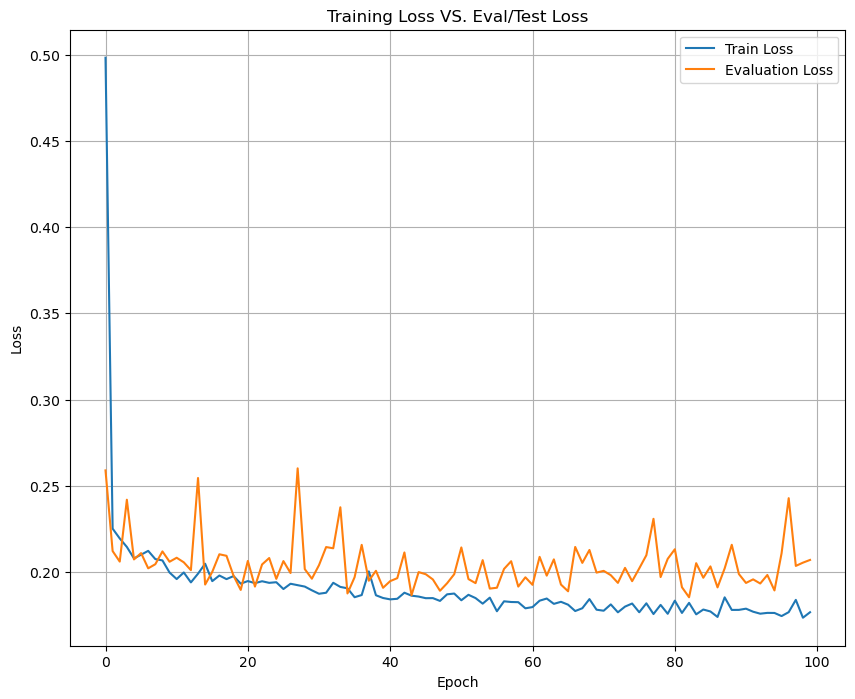

In [322]:
# Plot Loss Curves
def plot_loss_curves(train_loss, val_loss):
    
    plt.figure(figsize=(10, 8))
    plt.plot(train_loss, label="Train Loss")
    plt.plot(val_loss, label="Evaluation Loss")
    plt.title("Training Loss VS. Eval/Test Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.show()

plot_loss_curves(train_loss=history["train_loss"], val_loss=history["dev_loss"])

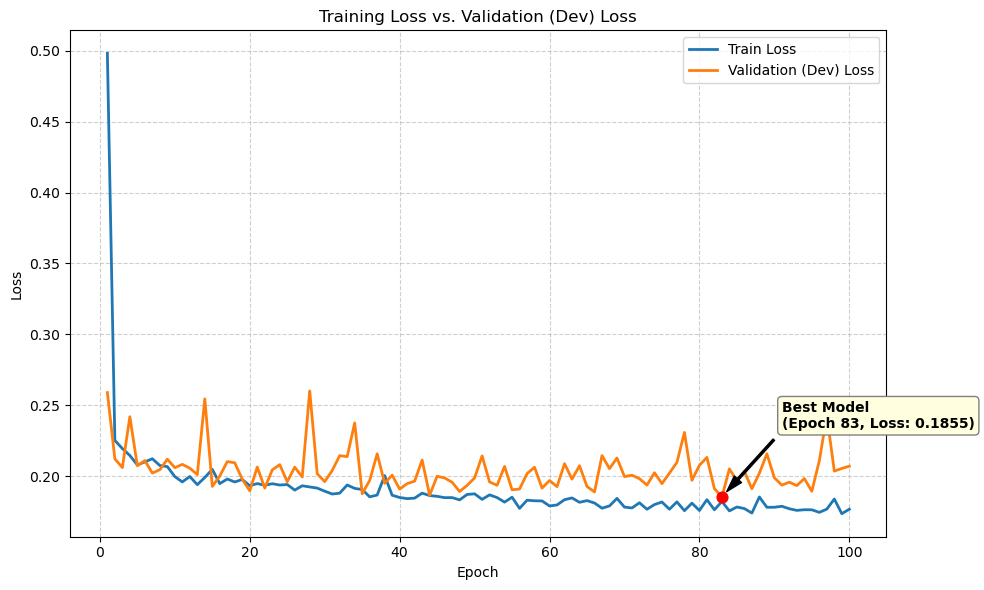

In [323]:
def plot_loss_curves(train_loss, val_loss):
    epochs = range(1, len(train_loss) + 1)

    # Find the exact epoch where the best model checkpoint was saved
    best_idx = int(np.argmin(val_loss))
    best_epoch = epochs[best_idx]
    best_loss = val_loss[best_idx]

    plt.figure(figsize=(10, 6))
    plt.plot(epochs, train_loss, label="Train Loss", linewidth=2)
    plt.plot(epochs, val_loss, label="Validation (Dev) Loss", linewidth=2)

    # Highlight the best checkpoint point
    plt.scatter(best_epoch, best_loss, color="red", s=60, zorder=5)

    # Add arrow pointing to the best checkpoint
    y_range = max(max(train_loss), max(val_loss)) - min(min(train_loss), min(val_loss))
    plt.annotate(
        f"Best Model\n(Epoch {best_epoch}, Loss: {best_loss:.4f})",
        xy=(best_epoch, best_loss),
        xytext=(best_epoch + len(epochs) * 0.08, best_loss + y_range * 0.15),
        arrowprops=dict(facecolor="black", shrink=0.08, width=1.5, headwidth=7),
        fontsize=10,
        fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="lightyellow", edgecolor="gray")
    )

    plt.title("Training Loss vs. Validation (Dev) Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.tight_layout()
    plt.show()


plot_loss_curves(train_loss=history["train_loss"], val_loss=history["dev_loss"])

# 7. Test The Model

Test Loss          : 0.2265
Test Accuracy      : 0.9227
F1-Score (Weighted): 0.9232
F1-Score (Macro)   : 0.9344

Classification Report:

              precision    recall  f1-score   support

    BARBUNYA     0.9333    0.9192    0.9262       198
      BOMBAY     1.0000    0.9872    0.9935        78
        CALI     0.9176    0.9551    0.9360       245
    DERMASON     0.9340    0.9041    0.9188       532
       HOROZ     0.9700    0.9283    0.9487       279
       SEKER     0.9567    0.9441    0.9503       304
        SIRA     0.8392    0.8965    0.8669       396

    accuracy                         0.9227      2032
   macro avg     0.9358    0.9335    0.9344      2032
weighted avg     0.9244    0.9227    0.9232      2032



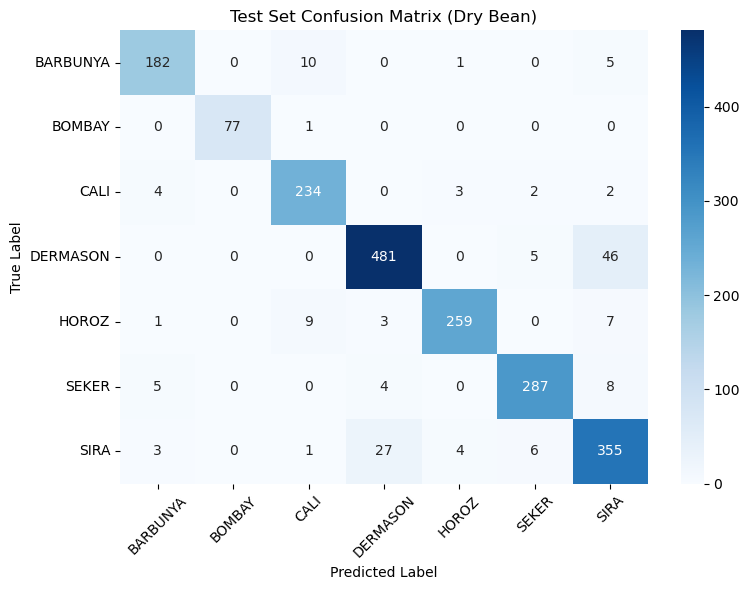

In [324]:
# 1. Evaluate on test set using the best saved model weights
test_loss, test_acc, y_true, y_preds = eval_step(
    model=model,
    data_loader=test_loader,
    criterion=criterion,
    device=device,
    return_preds=True
)

# 2. Calculate multi-class metrics
f1_weighted = f1_score(y_true, y_preds, average="weighted")
f1_macro = f1_score(y_true, y_preds, average="macro")
report = classification_report(y_true, y_preds, target_names=class_names, digits=4)
cm = confusion_matrix(y_true, y_preds)

print(f"Test Loss          : {test_loss:.4f}")
print(f"Test Accuracy      : {test_acc:.4f}")
print(f"F1-Score (Weighted): {f1_weighted:.4f}")
print(f"F1-Score (Macro)   : {f1_macro:.4f}")
print("\nClassification Report:\n")
print(report)

# 3. Plot 7x7 Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Test Set Confusion Matrix (Dry Bean)")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# 8. Save/Load and Compare The Best Model With Loaded

## 8.1. Save

In [326]:
# 1.Creating models directory
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

# 2. Creating model saving path
MODEL_NAME = "best_model.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

# 3. Saving (only weights `state_dict`)
print(f"Saving Model To: {MODEL_SAVE_PATH}")
torch.save(obj=model.state_dict(), f=MODEL_SAVE_PATH)

Saving Model To: models/best_model.pth


## 8.2. Load

In [329]:
# Instantiate a new Obj
loaded_model = DryBeenClassifier()

# Upload loaded to cuda
loaded_model.to(device)

loaded_model.load_state_dict(torch.load(f=MODEL_SAVE_PATH, weights_only=True))

print(f"Loaded Model: {loaded_model}")

Loaded Model: DryBeenClassifier(
  (layer1): Linear(in_features=16, out_features=32, bias=True)
  (layer2): Linear(in_features=32, out_features=16, bias=True)
  (layer3): Linear(in_features=16, out_features=8, bias=True)
  (layer4): Linear(in_features=8, out_features=7, bias=True)
  (relu): ReLU()
)


## 8.3. Compare (Models & Outputs)

In [331]:
# 1. Verify That all parameters are equal
has_mismatch = any(
    (loaded_model.state_dict()[k] == model.state_dict()[k]).all().item()
    for k in model.state_dict()
)

print(f"Any mismatched weights? {has_mismatch}")  # Expected: False

Any mismatched weights? True


In [334]:
# 2. Verify That all outputs on test are the same (it should be since all params are equal)
test_features_batch, test_labels_batch = next(iter(test_loader))
test_features_batch, test_labels_batch = test_features_batch.to(device), test_labels_batch.to(device)

y_preds = model(test_features_batch)
y_loaded_preds = model(test_features_batch)

(y_preds == y_loaded_preds).all().item()

True